In [2]:
%matplotlib widget

import os
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.widgets import PolygonSelector

from FlowCytometryTools import FCMeasurement


In [ ]:
# Import fcs files

def load_fcs_file(fcs_path):
    """Load a single .fcs file into a pandas DataFrame."""
    sample = FCMeasurement(ID='Test Sample', datafile=fcs_path)
    return sample.data

def load_fcs_directory(directory_path):
    """Load all .fcs files in a directory into a dict of DataFrames."""
    fcs_dict = {}
    for file in sorted(os.listdir(directory_path)):
        if file.lower().endswith(".fcs"):
            fcs_dict[file] = load_fcs_file(os.path.join(directory_path, file))
    return fcs_dict


# Define location of fcs files

fcs_dir = r"C:\Users\UserID\Desktop\Cytometry Data\Experiment"
fcs_data = load_fcs_directory(fcs_dir)


In [3]:
# Gate population by drawing a polygon

class InteractiveGater:
    def __init__(self, df, x_col='FSC-A', y_col='SSC-A'):
        self.df          = df
        self.x_col       = x_col
        self.y_col       = y_col
        self.fig, self.ax = plt.subplots()
        self.verts        = None
        self.mask         = None
        self.scatter_gated = None
        self.selector = PolygonSelector(
            self.ax, self.onselect, useblit=True,
            props=dict(color='r', linewidth=2)
        )
        self.cid = self.fig.canvas.mpl_connect('key_press_event', self.on_key_press)

    def onselect(self, verts):
        self.verts = verts
        path   = Path(verts)
        points = self.df[[self.x_col, self.y_col]].to_numpy()
        self.mask = path.contains_points(points)

        if self.scatter_gated:
            self.scatter_gated.remove()
        self.scatter_gated = self.ax.scatter(
            self.df.loc[self.mask, self.x_col],
            self.df.loc[self.mask, self.y_col],
            s=1, c='lime', label='Gated'
        )
        self.ax.legend()
        self.fig.canvas.draw()

    def on_key_press(self, event):
        if event.key == 'r':
            print("Resetting gate")
            self.reset_gate()

    def reset_gate(self):
        self.verts = None
        self.mask  = None
        if self.scatter_gated:
            self.scatter_gated.remove()
            self.scatter_gated = None
        self.selector.disconnect_events()
        self.selector = PolygonSelector(
            self.ax, self.onselect, useblit=True,
            props=dict(color='r', linewidth=2)
        )
        if self.ax.legend_:
            self.ax.legend_.remove()
        self.fig.canvas.draw()

    def show(self):
        self.ax.scatter(self.df[self.x_col], self.df[self.y_col],
                        s=1, alpha=0.2, label='All Events')
        self.ax.set_xlabel(self.x_col)
        self.ax.set_ylabel(self.y_col)
        self.ax.set_title("Draw polygon with mouse. Close shape to gate. Press r to reset.")
        self.ax.set_xscale('log')
        self.ax.set_yscale('log')
        self.ax.legend()
        plt.show()

    def get_gated_data(self):
        if self.mask is not None:
            return self.df[self.mask].copy()
        print("No gate defined")
        return pd.DataFrame()

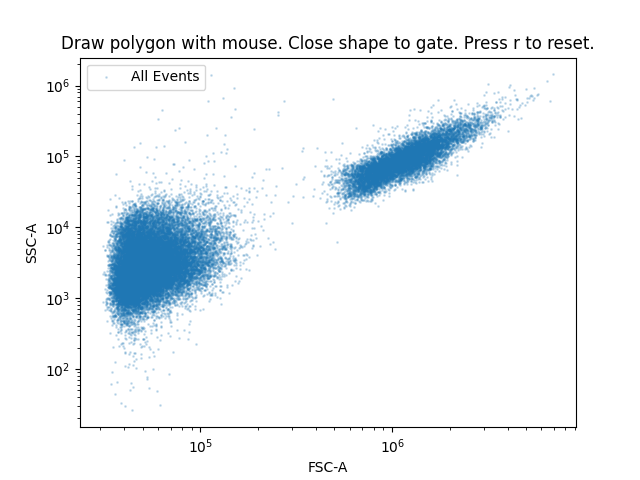

No gate defined


In [3]:
# Choose a representative sample to define the gate

df_gate = load_fcs_file(
    r"C:\Users\UserID\Desktop\Cytometry Data\Experiment\A01 Test.fcs"
)

gater = InteractiveGater(df_gate, x_col='FSC-A', y_col='SSC-A')
gater.show()


gated_df = gater.get_gated_data()

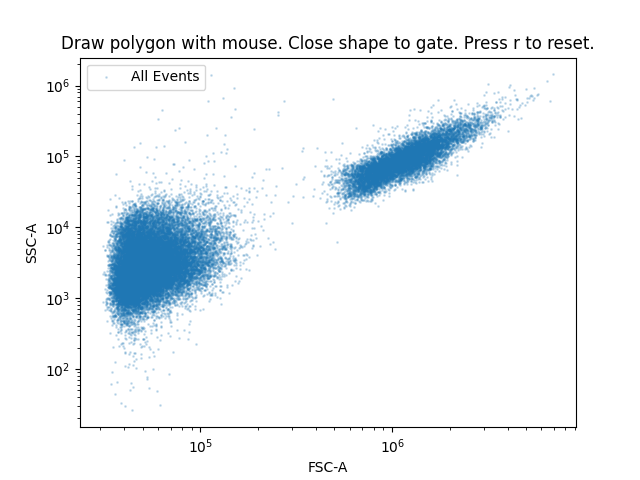

No gate defined


In [4]:
# # Used the following sample for gating Fig 4C

# df_gate = load_fcs_file(
#     r"C:\Users\C837471923\Desktop\Cytometry Data\251222_Coculture9_IAMDR\F07 3hrs_uninduced.fcs"
# )

# gater = InteractiveGater(df_gate, x_col='FSC-A', y_col='SSC-A')
# gater.show()

# gated_df = gater.get_gated_data()

In [4]:
# Save gate as a pickle 


gate_folder = "gates"
os.makedirs(gate_folder, exist_ok=True)

gate_name = "test_gate.pkl"  
gate_path = os.path.join("gates", gate_name)
with open(gate_path, "wb") as f:
    pickle.dump(gater.verts, f)

In [6]:
# Apply gate to all data


def apply_polygon_gate(df, x_col, y_col, polygon_vertices):

    if polygon_vertices is None:
        raise ValueError("No polygon gate defined.")
    path   = Path(polygon_vertices)
    points = df[[x_col, y_col]].to_numpy()
    mask   = path.contains_points(points)
    return df[mask].copy()

if 'gater' in dir() and gater.verts is not None:
    polygon_vertices = gater.verts
    print("Using freshly drawn gate.")
else:
    print("gater not found — load a saved gate.")

fcs_data      = load_fcs_directory(fcs_dir)
gated_data    = {}
desired_count = 10000

for file_name, df in fcs_data.items():
    gated_df = apply_polygon_gate(df, x_col='FSC-A', y_col='SSC-A',
                                  polygon_vertices=polygon_vertices)
    if gated_df.shape[0] >= desired_count:
        gated_df = gated_df.sample(n=desired_count, random_state=42)
        print(f"{file_name}: Downsampled to {desired_count} events.")
    else:
        print(f"{file_name}: Only {gated_df.shape[0]} events inside gate.")
    gated_data[file_name] = gated_df



gater not found — load a saved gate.
D03 Blank.fcs: Only 12 events inside gate.
D04 CY_Uninduced_d1in300.fcs: Only 4 events inside gate.
D05 Cy_4uMIAM_d1in300.fcs: Only 11 events inside gate.
D06 Cy_20uMIAM_d1in300.fcs: Only 11 events inside gate.
D07 Cy_100uMIAM_d1in300.fcs: Only 9 events inside gate.
D08 Cy_500uMIAM_d1in300.fcs: Only 3 events inside gate.
D09 Cy_1mMTheo_DMSO_d1in300.fcs: Only 11 events inside gate.
D10 YPH499_d1in50.fcs: Only 701 events inside gate.
D11 1hrs_Uninducedd1i5.fcs: Downsampled to 10000 events.
D12 1hrs_4uMIAM-didnotaddyeast.fcs: Only 33 events inside gate.
E01 1hrs_20uMIAM.fcs: Downsampled to 10000 events.
E02 1hrs_100uMIAM.fcs: Downsampled to 10000 events.
E03 1hrs_500umIAM.fcs: Downsampled to 10000 events.
E04 1hrs_Uninduced+0.1uMIAA.fcs: Downsampled to 10000 events.
E05 1hrs_Uninduced+1uMIAA.fcs: Downsampled to 10000 events.
E06 1hrs_Uninduced+10uMIAA.fcs: Downsampled to 10000 events.
E07 1hrs_Uninduced+100uMIAA.fcs: Downsampled to 10000 events.
E08 1h

In [5]:
# Gate that was used for Fig 4C

# gate_path = os.path.join("gates", "251222_3hrs_Uninduced_gate.pkl")  

# with open(gate_path, "rb") as f:
#     polygon_vertices = pickle.load(f)

# fcs_data     = load_fcs_directory(fcs_dir)
# gated_data   = {}
# desired_count = 10000

# for file_name, df in fcs_data.items():
#     path   = Path(polygon_vertices)
#     points = df[['FSC-A', 'SSC-A']].to_numpy()
#     mask   = path.contains_points(points)
#     gated_df = df[mask].copy()

#     gated_data[file_name] = gated_df


In [7]:
# Ratiometric analysis

min_percp_threshold = 1e-6
normalized_data = {}

for name, df in gated_data.items():

        df = df.copy()
        df = df[df['PerCP-A'] > min_percp_threshold]
        df['FITC_PerCP_Ratio'] = df['FITC-A'] / df['PerCP-A']

        normalized_data[name] = df


In [8]:
# Summary statistics

summary_stats = []

for name, df in normalized_data.items():
    df = df.copy()

    all_ratios = df['FITC_PerCP_Ratio']
    n_total    = len(all_ratios)

    median_ratio = all_ratios.median()
    mean_ratio   = all_ratios.mean()
    std_ratio    = all_ratios.std(ddof=1) if n_total > 1 else np.nan
    sem_ratio    = std_ratio / np.sqrt(n_total) if n_total > 1 else np.nan

    summary_stats.append({
        'Sample'      : name,
        'Median Ratio': median_ratio,
        'Mean Ratio'  : mean_ratio,
        'Std Ratio'   : std_ratio,
        'SEM Ratio'   : sem_ratio,
    })

summary_df = pd.DataFrame(summary_stats)
print(summary_df)

                                Sample  Median Ratio  Mean Ratio  Std Ratio  \
0                        D03 Blank.fcs      0.307692    0.556208   0.562438   
1         D04 CY_Uninduced_d1in300.fcs      0.011210    0.064899   0.095611   
2            D05 Cy_4uMIAM_d1in300.fcs      0.008951    0.391304   1.104125   
3           D06 Cy_20uMIAM_d1in300.fcs      0.008588    0.008686   0.001921   
4          D07 Cy_100uMIAM_d1in300.fcs      0.007550    0.008299   0.002336   
5          D08 Cy_500uMIAM_d1in300.fcs      0.011470    0.213398   0.351304   
6      D09 Cy_1mMTheo_DMSO_d1in300.fcs      0.007114    0.028207   0.057880   
7                D10 YPH499_d1in50.fcs     22.690069   23.040039   6.604484   
8           D11 1hrs_Uninducedd1i5.fcs     14.713391   15.557014   6.656099   
9   D12 1hrs_4uMIAM-didnotaddyeast.fcs     12.628415   12.772423   7.027613   
10                E01 1hrs_20uMIAM.fcs      9.464430   10.561115  21.044506   
11               E02 1hrs_100uMIAM.fcs      7.752593

In [9]:
# Summary stats save as pickle and xls


analysis_folder = "analysis_cache"
os.makedirs(analysis_folder, exist_ok=True)

prefix = "Test_pickle_analysis"

norm_path    = os.path.join(analysis_folder, f"{prefix}_normalized_data.pkl")
summary_path = os.path.join(analysis_folder, f"{prefix}_summary_df.pkl")
excel_path   = os.path.join(analysis_folder, f"{prefix}_summary_df.xlsx")

with open(norm_path, "wb") as f:
    pickle.dump(normalized_data, f)

with open(summary_path, "wb") as f:
    pickle.dump(summary_df, f)

summary_df.to_excel(excel_path, index=False)
